# 05 · Preparación y ejecución de COPERT

En [04](04_servicio_y_actividad.ipynb) he comprobado **qué servicio transporta a las personas y qué kilómetros recorre**. Ahora obtengo y compruebo los factores que permiten asignar energía a esa actividad. COPERT es el programa utilizado para calcular el consumo energético de categorías de vehículos bajo condiciones técnicas definidas. Un **factor en MJ/km** expresa megajulios de energía por kilómetro de vehículo; no es todavía el consumo anual del transporte al Parque.

**Recibe:** el registro de ejecución, los CSV (tablas de texto delimitadas) completos y tipados de Bronze y la referencia de comparación separada en Silver. **Produce:** factores normalizados y su comparación; al ejecutar el motor, también entradas nativas, exportaciones y registros de las 34 consultas. **Comprueba:** integridad de entradas, categorías, condiciones, correspondencia de todos los factores y tolerancia numérica. Se mantienen las **2.500.000 visitas-persona anuales** y las 31 condiciones; aquí no recalculo el balance ni cambio la programación de transporte.

Las celdas llaman al productor común de [etapas_registradas.py](../src/movilidad_teide/flujos/etapas_registradas.py) y a las funciones de [copert_publico.py](../src/movilidad_teide/vehiculos/copert_publico.py). La ejecución programática está en [copert_ejecucion.py](../src/movilidad_teide/vehiculos/copert_ejecucion.py). Los factores y sus normalizaciones no se vuelven a implementar en el cuaderno.


## 1. Elegir la acción y la ejecución

La tabla 1a distingue tres acciones. **Consultar no ejecuta COPERT.** Para obtener factores nuevos hay que elegir expresamente `ejecutar_motor`, indicar el ejecutable instalado y un intercambio nuevo en una unidad local de Windows. La preparación de los archivos nativos forma parte de esa acción: se reconstruyen desde los CSV y sus tipos antes de cada consulta.

**Tabla 1a. Acciones del cuaderno COPERT y resultado que acreditan.** El registro procede de 00; las hipótesis siguen en el Excel. Una etapa 05 completada se conserva y no se sobrescribe.

| Acción en la celda de controles | Qué realiza | ¿Lanza COPERT ahora? | Qué necesita |
|---|---|---|---|
| `consultar` —opción inicial— | Lee los productos aceptados de 05 y muestra su procedencia y comprobaciones | No | 05 completada en el registro elegido |
| `comprobar_factores` | Repite la comparación y normalización de los factores distribuidos, sin releer las exportaciones XLSX originales | No | Registro con 05 pendiente; entradas Bronze y factores y referencia Silver |
| `ejecutar_motor` | Reconstruye las 34 entradas XLSX, ejecuta COPERT y compara sus factores | Sí | Registro con 05 pendiente; COPERT 5.10.1 instalado, Windows/WSL y un intercambio local nuevo |

El formato XLSX es el libro nativo que recibe el programa. Los CSV no se importan uno a uno manualmente: `estructura.json` conserva el orden de hojas y los tipos necesarios para reconstruir cada libro. La tabla anual de visitas no es una entrada de estas consultas técnicas.

04 precede a 05 para comprender la actividad antes de su energía. **Las consultas técnicas ya están fijadas y son autocontenidas:** la acción de 05 no depende de haber completado 01–04. Para calcular después el balance de 06 sí deben estar completadas 01–05 en la misma ejecución; no se mezclan bibliotecas de otra carpeta.


In [1]:
from pathlib import Path
import sys, json, hashlib, shutil, subprocess, tempfile
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ = next((p for p in candidatas if (p / "pyproject.toml").is_file()
             and (p / "config/parametros_modelo.xlsx").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este cuaderno desde la raíz del proyecto o desde notebooks/.")
sys.path.insert(0, str(RAIZ / "src"))
from movilidad_teide.configuracion.registro import abrir_ejecucion
from movilidad_teide.flujos.etapas_registradas import ejecutar_etapa
from movilidad_teide.vehiculos.copert_publico import verify_package, import_workbook
from movilidad_teide.vehiculos.copert_entrada import inspect_input
from movilidad_teide.vehiculos.copert_ejecucion import windows_path


In [2]:
ACCION_COPERT = "consultar"  # Otras acciones: "comprobar_factores" o "ejecutar_motor".
RUTA_EJECUCION = Path("data/silver/ejecuciones/referencia_2028_final_20261116")
EJECUTABLE_COPERT = None  # Para ejecutar: Path con la ubicación real de COPERT.exe.
INTERCAMBIO_WINDOWS = None  # Para ejecutar: Path nuevo bajo una unidad /mnt/c/, /mnt/d/, etc.


In [3]:
if ACCION_COPERT not in {"consultar", "comprobar_factores", "ejecutar_motor"}:
    raise ValueError('Elija consultar, comprobar_factores o ejecutar_motor en ACCION_COPERT.')
EJECUCION = RAIZ / RUTA_EJECUCION
if not (EJECUCION / "registro_ejecucion.json").is_file():
    raise FileNotFoundError("No existe el registro elegido. Inicie una ejecución en00 e indique aquí su ruta.")
DATOS = abrir_ejecucion(RAIZ, EJECUCION)
ETAPA_INICIAL = DATOS["estado_etapas"]["etapas"]["05"]
if ACCION_COPERT == "consultar" and ETAPA_INICIAL["estado"] != "completada":
    raise ValueError("05 no está completada. Elija comprobar_factores o ejecutar_motor en esta ejecución.")
if ACCION_COPERT != "consultar" and ETAPA_INICIAL["estado"] == "completada":
    raise ValueError("05 ya está completada; no se sustituye su biblioteca. Inicie otra ejecución en00.")
if ACCION_COPERT != "consultar" and ETAPA_INICIAL["estado"] == "en_curso":
    raise ValueError("Hay un intento05 en curso. Revise su estado y el proceso antes de volver a ejecutar.")
CFG = DATOS["configuracion"]["valores"]
PAQUETE = RAIZ / "data/bronze/copert/entradas_publicas"
MANIFIESTO = verify_package(PAQUETE)
CONSULTAS = pd.read_csv(PAQUETE / "consultas.csv", sep=";")
VEHICULOS = pd.read_csv(PAQUETE / "vehiculos.csv", sep=";")
print("Acción solicitada:", ACCION_COPERT)
print("Ejecución:", DATOS["registro"]["identificador"])
print("Visitas-persona de referencia, sin y con intervención:", CFG["visitas_anio"])
print("Condiciones efectivas conservadas:", len(CFG))
print("Consultas técnicas de entradas verificadas:", len(MANIFIESTO["consultas"]))
def mostrar(tabla, titulo, formatos=None):
    display(tabla.style.set_uuid("copert05").hide(axis="index").set_caption(titulo)
            .format(formatos or {}, decimal=",", thousands=" ", na_rep="No procede"))


Acción solicitada: consultar
Ejecución: referencia_2028_paquetes_20261116
Visitas-persona de referencia, sin y con intervención: 2500000
Condiciones efectivas conservadas: 31
Consultas técnicas de entradas verificadas: 34


## 2. Dónde están las entradas y las salidas

**Bronze conserva las entradas originales. Silver conserva las transformaciones, las ejecuciones y las comparaciones.** La tabla siguiente permite seguir la cadena sin depender de carpetas privadas de desarrollo. Las rutas son iguales en ambas copias del proyecto y parten de su raíz.

**Tabla 1b. Ubicación de las entradas y resultados COPERT de la referencia del Teide (2028).** Fuente: estructura Medallion y registro de ejecución.

| Archivo o carpeta | Función en este paso |
|---|---|
| `data/bronze/copert/entradas_publicas/consultas.csv` | Índice legible de las 34 consultas, condiciones y uso |
| `data/bronze/copert/entradas_publicas/vehiculos.csv` | Identificación completa de las categorías nativas de COPERT |
| `data/bronze/copert/entradas_publicas/tablas/` | Todos los CSV por consulta y su `estructura.json`; el motor recibe los XLSX reconstruidos desde aquí |
| `data/bronze/copert/entradas_publicas/manifiesto.json` | Configuración y huellas SHA-256 de las entradas; una huella identifica el contenido de cada archivo |
| `data/silver/copert/referencia_comparacion/` | Factores esperados utilizados para comparar; no son entradas del motor ni producen sus resultados |
| `data/silver/copert/factores/` | Factores normalizados distribuidos; los utiliza la acción `comprobar_factores` |
| `data/silver/copert/ejecuciones/consultas/` | Libros de entrada, exportaciones y registros del motor distribuidos con la referencia |
| Carpeta de resultados de 05 en el registro elegido | Bibliotecas y comprobación aceptadas que recibirá 06; con motor nuevo incorpora también sus consultas y registros |
| Intercambio nuevo de Windows, solo para motor | Carpeta de trabajo local exigida por COPERT; tras el éxito se copia íntegra al intento de 05 |

El intercambio de Windows es una necesidad de la interfaz del programa, no una cuarta capa de datos. Los productos aceptados quedan en Silver o en el destino externo identificado por el registro. Gold no se utiliza para obtener estos factores y no se modifica.


## 3. Qué condiciones se consultan y para qué

Una consulta puede producir muchos factores: combina categorías de vehículos, tecnologías y modos nativos de circulación. Por eso **34 consultas producen 5.294 factores**, no 34 factores. La tabla 2 muestra todas las consultas y su papel; conserva también las que completan la malla técnica o comprueban su linealidad, separadas de las utilizadas directamente en el consumo.

Los turismos del estudio utilizan **20, 40 y 80 km/h**. Los nodos de 60 y 100 km/h completan la malla que utiliza el preparador; no se asignan como velocidades de circulación a esos recorridos. Los autocares se consultan a **34 km/h**. Estas velocidades energéticas no sustituyen los tiempos de los itinerarios comprobados en 04.

**Tabla 2. Condiciones de las 34 consultas COPERT de la referencia del Teide, año 2028.** Fuente: índice de entradas Bronze verificado. Pendiente en porcentaje; carga y control primario en fracción. La actividad técnica de 17 km por categoría normaliza el factor y no representa actividad anual del servicio.


In [4]:
tabla_consultas = CONSULTAS.drop(columns=["Consulta"]).copy()
tabla_consultas.insert(0, "N.º de consulta en el índice", np.arange(1,len(tabla_consultas)+1))
mostrar(tabla_consultas, "Tabla 2 · Consultas COPERT completas · Teide, 2028 · Fuente: consultas.csv de Bronze",
        {"Velocidad técnica (km/h)":"{:,.0f}","Pendiente (%)":"{:,.0f}","Carga técnica (fracción)":"{:,.2f}","Control primario técnico":"{:,.2f}","Actividad técnica (km)":"{:,.0f}"})


N.º de consulta en el índice,Tipo,Año,Velocidad técnica (km/h),Pendiente (%),Carga técnica (fracción),Control primario técnico,Actividad técnica (km),Categorías consultadas,Uso
1,Autocar,2 028,34,-6,"0,50",No procede,17,1,Factor utilizado en el consumo
2,Autocar,2 028,34,-4,"0,50",No procede,17,1,Factor utilizado en el consumo
3,Autocar,2 028,34,-2,"0,50",No procede,17,1,Factor utilizado en el consumo
4,Autocar,2 028,34,0,"0,50",No procede,17,1,Factor utilizado en el consumo
5,Autocar,2 028,34,2,"0,50",No procede,17,1,Factor utilizado en el consumo
6,Autocar,2 028,34,4,"0,50",No procede,17,1,Factor utilizado en el consumo
7,Autocar,2 028,34,6,"0,50",No procede,17,1,Factor utilizado en el consumo
8,Autocar,2 028,34,-6,"0,00",No procede,17,1,Factor utilizado en el consumo
9,Autocar,2 028,34,-4,"0,00",No procede,17,1,Factor utilizado en el consumo
10,Autocar,2 028,34,-2,"0,00",No procede,17,1,Factor utilizado en el consumo


La **carga técnica del autocar** es un parámetro de COPERT: se consulta 0 para los desplazamientos en vacío y 0,5 para los comerciales. **No significa una ocupación del 50 % de las plazas**; la ocupación de pasajeros se calcula en 04 con 46 plazas comerciales por expedición. Se emplea una categoría técnica de autocar: diésel estándar de hasta 18 toneladas, norma Euro VI D/E. Sus etiquetas nativas en inglés se conservan en el CSV de vehículos para identificarla sin ambigüedad; no certifican cada autobús real que vaya a contratarse.

El **control primario de vehículos multienergía** es un ajuste técnico diferente. Se consultan los extremos 0 y 1 y el punto 0,37 para comprobar la combinación lineal. Esos números no son un reparto energético observado ni nuevas hipótesis de movilidad. El valor de referencia elegido se aplica después mediante el código del estudio.

Las siete pendientes de autocar van de −6 % a +6 %. Las líneas 342 y 348 de TITSA —Transportes Interurbanos de Tenerife— y las lanzaderas utilizan estos factores según el perfil dirigido del recorrido. Las excursiones mantienen el factor de pendiente cero en ambos escenarios principales; no significa que sus carreteras sean llanas. Esta simplificación afecta a su consumo absoluto y a la sensibilidad de crecimiento; al mantener la misma actividad sin/con, el bloque de excursiones se cancela en el ahorro principal.

Los factores de turismos son nativos, sin el ajuste físico propio de pendiente del estudio. Ese ajuste se aplica fuera de COPERT en 06; no se atribuye al motor. Los factores por servicio y escenario se reutilizan sobre su actividad correspondiente: **no se duplica el consumo por compartir una categoría técnica**.


## 4. Cómo se reconstruye una entrada nativa

Los CSV usan UTF-8, una codificación de texto que conserva los acentos, con marca de codificación, separador punto y coma y punto decimal. `estructura.json` conserva el orden de hojas y el tipo de cada celda: texto, entero, decimal, booleano o vacío. Un vacío no se convierte en cero y una cabecera textual como `2028` no se confunde con un número. Las entradas completas no requieren un proyecto previo ni valores heredados de una sesión manual. Estos libros nativos son archivos generados para el motor; las hipótesis del estudio se siguen editando únicamente en el Excel de configuración.

Algunas hojas nativas muestran `[%]` pero reciben fracciones:0,5 representa el 50% y 0,06 una pendiente del 6%. La tabla 2 ya expresa la pendiente como porcentaje y la carga/control como fracciones. No convierto unidades por el aspecto de una cifra.

La inspección siguiente reconstruye **una entrada de ejemplo en una carpeta temporal**, la lee y elimina solo esa copia temporal al terminar. No escribe Bronze ni completa 05, y no ejecuta COPERT. Se elige el autocar comercial con pendiente cero, que también suministra el factor de excursiones. Al ejecutar el motor se reconstruyen automáticamente las 34 entradas en su destino nuevo, no solo este ejemplo.

**Tabla 3. Hojas principales de la entrada reconstruida de autocar comercial a 34 km/h y pendiente 0%,2028.** Fuente: CSV tipados y estructura de esa consulta. Se muestran las hojas de identificación, actividad, reparto, velocidad, pendiente, carga y combustible; todas las demás permanecen en el paquete y se reconstruyen igualmente.


In [5]:
ejemplo = next(x for x in MANIFIESTO["consultas"] if x["tipo"]=="explicit_bus_reference"
               and x["configuracion"]["load_fraction"]==0.5 and x["configuracion"]["slope_pct"]==0)
with tempfile.TemporaryDirectory(prefix="teide_entrada_copert_") as temporal:
    archivo = Path(temporal) / "entrada.xlsx"
    import_workbook(PAQUETE / ejemplo["carpeta_csv"], archivo)
    INSPECCION = inspect_input(archivo)
seleccion_hojas = ["SHEETS","STOCK","MEAN_ACTIVITY","RURAL_SHARE","RURAL_SPEED","RURAL_ROAD_SLOPE","RURAL_LOAD","FB~FUEL_BALANCE"]
hojas = pd.DataFrame([{"Hoja nativa":k,"Filas (incluida cabecera)":v["rows"],"Columnas":v["columns"]}
                       for k,v in INSPECCION["sheets"].items() if k in seleccion_hojas])
mostrar(hojas,"Tabla 3 · Inspección de la entrada XLSX reconstruida · Autocar,34 km/h,carga técnica 0,5,pendiente0%,2028")
print("Hojas completas reconstruidas en el ejemplo:",len(INSPECCION["sheets"]))
print("Hojas requeridas ausentes:", INSPECCION["missing_required_sheets"])
assert not INSPECCION["missing_required_sheets"]


Hoja nativa,Filas (incluida cabecera),Columnas
SHEETS,84,2
STOCK,2,5
RURAL_SHARE,2,5
RURAL_LOAD,2,5
RURAL_ROAD_SLOPE,2,5
FB~FUEL_BALANCE,2,1
MEAN_ACTIVITY,2,5
RURAL_SPEED,2,5


Hojas completas reconstruidas en el ejemplo: 84
Hojas requeridas ausentes: []


La actividad técnica mantiene **stock de una unidad y 17 km por categoría**, con el reparto de modos nativos que figura en las entradas de turismos. Solo sirve para obtener factores comparables; no introduce otra flota o más visitas. Las condiciones de ambiente y combustible conservan las de la referencia, incluida la especificación técnica de combustible de 1996; no se presentan como mediciones del Teide ni como previsión del combustible disponible en 2028.

Los detalles nativos completos están en los CSV y en su estructura. La [guía COPERT](../docs/reproduccion_copert.md) explica la interfaz y los comandos alternativos. La metodología del programa es la referencia para sus operaciones internas; este cuaderno se centra en las decisiones del estudio y en cómo repetirlas.


## 5. Ejecutar la acción elegida y registrar su procedencia

Para `ejecutar_motor` compruebo antes que el ejecutable existe, su versión corresponde a 5.10.1 y el intercambio es una ruta local nueva de Windows. La interfaz se prueba desde WSL, el entorno Linux de Windows, con `wslpath` y PowerShell disponibles. El ejecutable instalado no se distribuye con el proyecto. La consulta y comparación de factores pueden realizarse sin instalar COPERT ni disponer de estas herramientas de Windows.

El motor muestra su avance consulta a consulta y conserva entradas, exportaciones, fechas, código de salida y huellas del ejecutable y de los archivos. La salida técnica nativa es `resultado.xlsx`; si corresponde se añade el desglose energético. La creación de archivos o un proceso iniciado no acreditan por sí solos éxito: **05 solo queda completada tras terminar y verificar todas las consultas**.

Una interrupción conserva el intento y su intercambio. Primero reviso su estado, los registros y si el proceso COPERT sigue activo. Este cuaderno utiliza un intercambio nuevo por intento y no adopta archivos incompletos. La reanudación de la herramienta autónoma se trata en la guía; no se confunde con sobrescribir una etapa registrada completada.


In [6]:
VERSION_MOTOR = None
if ACCION_COPERT == "ejecutar_motor":
    if EJECUTABLE_COPERT is None or INTERCAMBIO_WINDOWS is None:
        raise ValueError("Indique EJECUTABLE_COPERT e INTERCAMBIO_WINDOWS antes de ejecutar el motor.")
    EJECUTABLE_COPERT = Path(EJECUTABLE_COPERT).resolve()
    INTERCAMBIO_WINDOWS = Path(INTERCAMBIO_WINDOWS).resolve()
    if not EJECUTABLE_COPERT.is_file():
        raise FileNotFoundError("No existe el ejecutable COPERT indicado.")
    if INTERCAMBIO_WINDOWS.exists():
        raise FileExistsError("El intercambio debe ser una carpeta nueva; no se sobrescriben ejecuciones.")
    if shutil.which("wslpath") is None or shutil.which("powershell.exe") is None:
        raise RuntimeError("La ejecución del motor requiere la interfaz Windows/WSL con wslpath y PowerShell.")
    ruta_exe_windows = windows_path(EJECUTABLE_COPERT)
    windows_path(INTERCAMBIO_WINDOWS)  # Rechaza intercambios UNC de Linux.
    literal = ruta_exe_windows.replace("'", "''")
    consulta_version = "(Get-Item -LiteralPath '"+literal+"').VersionInfo | Select-Object ProductVersion,FileVersion | ConvertTo-Json"
    VERSION_MOTOR = json.loads(subprocess.check_output(["powershell.exe","-NoProfile","-NonInteractive","-Command",consulta_version],text=True))
    if ".".join(VERSION_MOTOR["ProductVersion"].split(".")[:3]) != MANIFIESTO["copert_version"]:
        raise ValueError("La versión instalada no corresponde a la referencia; no se presupone equivalencia.")
    print("Versión del motor verificada:",VERSION_MOTOR["ProductVersion"])
else:
    print("La acción elegida no requiere ni lanza el motor COPERT.")


La acción elegida no requiere ni lanza el motor COPERT.


In [7]:
MOTOR_EN_ESTA_LLAMADA = False
if ACCION_COPERT == "comprobar_factores":
    ejecutar_etapa(RAIZ, EJECUCION, "05", accion="consultar")
elif ACCION_COPERT == "ejecutar_motor":
    ejecutar_etapa(RAIZ, EJECUCION, "05", accion="ejecutar_motor",
                  copert=EJECUTABLE_COPERT, intercambio=INTERCAMBIO_WINDOWS)
    MOTOR_EN_ESTA_LLAMADA = True
DATOS = abrir_ejecucion(RAIZ, EJECUCION)
ETAPA = DATOS["estado_etapas"]["etapas"]["05"]
if ETAPA["estado"] != "completada":
    raise RuntimeError("05 no se ha completado; no se presentan factores como aceptados.")
FACTORES = EJECUCION / ETAPA["carpeta"]
VERIFICACION = json.loads((FACTORES / "verificacion_copert.json").read_text())
COMPARACION = pd.read_csv(FACTORES / "comparacion_factores.csv",sep=";",float_precision="round_trip")
BIBLIOTECAS = {"Turismos":pd.read_parquet(FACTORES / "factores_turismos.parquet"),
               "Multienergía":pd.read_parquet(FACTORES / "factores_multienergia.parquet"),
               "Autocar":pd.read_parquet(FACTORES / "factores_autocar.parquet")}
MOTOR_ORIGEN_ETAPA = ETAPA["resultado"]["motor_ejecutado_en_esta_ejecucion"]
assert MOTOR_ORIGEN_ETAPA == (ETAPA["accion"]=="ejecutar_motor")
print("Acción de este cuaderno:",ACCION_COPERT)
print("Motor ejecutado al pasar por estas celdas:",MOTOR_EN_ESTA_LLAMADA)
print("Origen de la etapa05 aceptada:",ETAPA["accion"])
print("Esta ejecución contiene una etapa05 con motor nuevo:",MOTOR_ORIGEN_ETAPA)
print("Carpeta de factores aceptados dentro del registro:",ETAPA["carpeta"])


Acción de este cuaderno: consultar
Motor ejecutado al pasar por estas celdas: False
Origen de la etapa05 aceptada: consultar
Esta ejecución contiene una etapa05 con motor nuevo: False
Carpeta de factores aceptados dentro del registro: resultados/05/ab7b8a70e5ef40c795f02f08881c0219


## 6. Qué se ha comprobado

La tabla 4 resume la correspondencia de los factores y las bibliotecas. La comparación exige una sola fila por combinación de categoría, tecnología, año, modo nativo, velocidad, pendiente, carga, control y consulta. Faltan/sobran filas o claves repetidas constituyen un error, aunque una media global pareciera coincidir. La **tolerancia absoluta es 10⁻¹²MJ/km**, sin tolerancia relativa; no se redondean factores para forzar igualdad.

El control de linealidad contrasta el punto 0,37 con la combinación de los extremos 0 y 1. La biblioteca de multienergía conserva los extremos necesarios y una sola representación del vehículo eléctrico de batería, sin duplicar sus factores. Por ello la suma de las filas de las tres bibliotecas no tiene por qué ser 5.294: las filas de control ya han cumplido su función de comprobación.

**Tabla 4. Comprobación de factores COPERT de la ejecución elegida.** Fuente: productos aceptados de 05. Las filas de bibliotecas son factores técnicos, no vehículos físicos, visitas ni expediciones anuales.


In [8]:
resumen = pd.DataFrame([
    ("Consultas verificadas", VERIFICACION["consultas"], "consultas"),
    ("Factores comparados", VERIFICACION["factores_comparados"], "filas"),
    ("Diferencia absoluta máxima", VERIFICACION["maxima_diferencia_mj_km"], "MJ/km"),
    ("Tolerancia absoluta", VERIFICACION["tolerancia_absoluta_mj_km"], "MJ/km"),
    *[("Biblioteca de "+nombre.lower(),len(tabla),"filas de factores") for nombre,tabla in BIBLIOTECAS.items()],
],columns=["Comprobación", "Valor", "Unidad"])
mostrar(resumen,"Tabla 4 · Factores y bibliotecas COPERT aceptados · Teide,referencia 2028",{"Valor":lambda x:f"{x:.12g}".replace(".",",")})
assert len(COMPARACION)==VERIFICACION["factores_comparados"]
assert COMPARACION.diferencia_absoluta_mj_km.le(VERIFICACION["tolerancia_absoluta_mj_km"]).all()
assert VERIFICACION["control_linealidad_verificado"]


Comprobación,Valor,Unidad
Consultas verificadas,34,consultas
Factores comparados,5294,filas
Diferencia absoluta máxima,0,MJ/km
Tolerancia absoluta,1e-12,MJ/km
Biblioteca de turismos,1560,filas de factores
Biblioteca de multienergía,2240,filas de factores
Biblioteca de autocar,14,filas de factores


La figura 1 permite interpretar el resultado de las consultas de autocar: compara la energía por kilómetro en los siete nodos de pendiente, a 34 km/h, con carga técnica 0 o 0,5. Son condiciones de cálculo, **no dos ocupaciones de pasajeros ni dos consumos anuales**. TITSA y las lanzaderas utilizan estos factores según sus recorridos; el factor plano de excursiones corresponde al nodo de pendiente cero con carga 0,5.


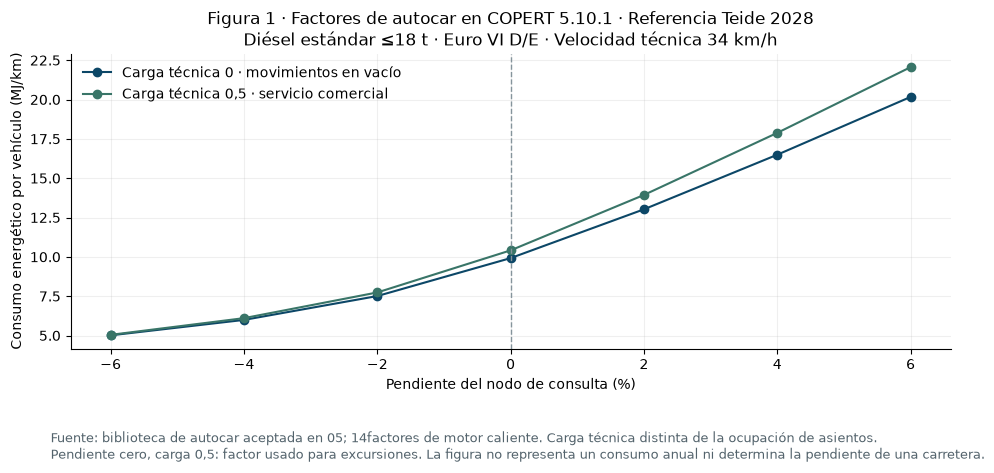

In [9]:
import matplotlib.pyplot as plt
bus = BIBLIOTECAS["Autocar"]
fig,ax = plt.subplots(figsize=(10,5))
for carga,color,etiqueta in [(0.,"#0C4767","Carga técnica 0 · movimientos en vacío"),(.5,"#397568","Carga técnica 0,5 · servicio comercial")]:
    grupo = bus.loc[bus.load_fraction.eq(carga)].sort_values("slope_class_pct")
    ax.plot(grupo.slope_class_pct,grupo.hot_ec_mj_per_km,marker="o",color=color,label=etiqueta)
ax.axvline(0,color="#85949C",linestyle="--",linewidth=1)
ax.set(title="Figura 1 · Factores de autocar en COPERT 5.10.1 · Referencia Teide 2028\nDiésel estándar ≤18 t · Euro VI D/E · Velocidad técnica 34 km/h",xlabel="Pendiente del nodo de consulta (%)",ylabel="Consumo energético por vehículo (MJ/km)",xticks=sorted(bus.slope_class_pct.unique()))
ax.grid(alpha=.2);ax.legend(frameon=False);ax.spines[["top","right"]].set_visible(False)
fig.text(.08,.02,"Fuente: biblioteca de autocar aceptada en 05; 14factores de motor caliente. Carga técnica distinta de la ocupación de asientos.\nPendiente cero, carga 0,5: factor usado para excursiones. La figura no representa un consumo anual ni determina la pendiente de una carretera.",fontsize=9,color="#53636C")
fig.subplots_adjust(bottom=.24,top=.83,left=.1,right=.98)
plt.show()


## 7. Cómo comprobar que realmente se ha ejecutado el motor

La celda de ejecución separa **la acción de ahora** del **origen de la etapa aceptada**. Si consulto una etapa que antes ejecutó COPERT, ahora solo la leo: no se atribuye otra ejecución al motor. `comprobar_factores` también deja explícito que utiliza los factores distribuidos. El indicador válido de motor nuevo es la acción completada `ejecutar_motor` en el registro, respaldada por las 34 ejecuciones y sus salidas.

En el resumen técnico del comprobador, `motor_copert_ejecutado` es un dato de procedencia de los factores distribuidos. Ese campo aislado **no prueba una ejecución nueva en esta llamada**. Este cuaderno utiliza el estado y la acción completada de 05 y comprueba su correspondencia con los registros nativos cuando los hay. El tipo de acción nunca se deduce de que la diferencia numérica sea cero.

**Tabla 5. Evidencias disponibles del motor que produjo la etapa 05 aceptada.** Si se están consultando factores distribuidos sin nuevas consultas en esa etapa, la tabla lo indica y remite a su procedencia Silver; no sustituye una ausencia por archivos de otra ejecución.


In [10]:
EVIDENCIA_MOTOR = None
if MOTOR_ORIGEN_ETAPA:
    ejecuciones_motor = json.loads((FACTORES / "ejecuciones.json").read_text())
    fuente_motor = json.loads((FACTORES / "fuente_paquete.json").read_text())
    assert len(ejecuciones_motor)==len(MANIFIESTO["consultas"])
    assert {r["consulta"] for r in ejecuciones_motor}=={r["nombre"] for r in MANIFIESTO["consultas"]}
    for caso in ejecuciones_motor:
        carpeta_caso = FACTORES / "consultas" / caso["consulta"]
        nativo = json.loads((carpeta_caso / "ejecucion.json").read_text())
        assert nativo["status"]=="exported" and nativo["returncode"]==0
        for nombre,huella in [("entrada.xlsx",caso["entrada_sha256"]),("resultado.xlsx",caso["salida_sha256"])]:
            assert hashlib.sha256((carpeta_caso / nombre).read_bytes()).hexdigest()==huella
        assert caso["ejecutable_sha256"]==fuente_motor["copert_sha256"]
    EVIDENCIA_MOTOR = {"consultas":len(ejecuciones_motor),"inicio_utc":min(x["inicio_utc"] for x in ejecuciones_motor),
                      "fin_utc":max(x["fin_utc"] for x in ejecuciones_motor),"ejecutable_sha256":fuente_motor["copert_sha256"]}
    tabla_motor = pd.DataFrame([{"Consultas con salida comprobada":EVIDENCIA_MOTOR["consultas"],
        "Inicio (UTC)":EVIDENCIA_MOTOR["inicio_utc"],"Fin (UTC)":EVIDENCIA_MOTOR["fin_utc"],"Ejecutable identificado por huella":"Sí"}])
    mostrar(tabla_motor,"Tabla 5 · Evidencia del motor de la etapa05 elegida · Todas las consultas terminadas y salidas comprobadas")
else:
    display(Markdown("**Tabla 5 · Evidencia de motor nuevo: no procede en esta etapa.** La acción aceptada compara factores distribuidos; sus exportaciones de origen están identificadas en `data/silver/copert/ejecuciones/consultas/`. No se presenta esa procedencia como motor ejecutado ahora."))


**Tabla 5 · Evidencia de motor nuevo: no procede en esta etapa.** La acción aceptada compara factores distribuidos; sus exportaciones de origen están identificadas en `data/silver/copert/ejecuciones/consultas/`. No se presenta esa procedencia como motor ejecutado ahora.

## 8. Localizar los resultados y continuar con el balance

La carpeta de factores mostrada al ejecutar contiene `comparacion_factores.csv`, `verificacion_copert.json` y las bibliotecas `factores_turismos.parquet`, `factores_multienergia.parquet` y `factores_autocar.parquet`. Parquet es un formato de tablas utilizado por el código; los CSV y las tablas del cuaderno facilitan su inspección. Con motor nuevo también aparecen `consultas/`, `ejecuciones.json`, `fuente_paquete.json` y `factores_nuevos.csv`. El registro de 05 identifica la ruta, el tamaño y la huella de cada producto aceptado.

Las celdas anteriores comprueban la parte COPERT. **El balance anual requiere además la actividad de 04, la demanda, la composición del parque y los ajustes físicos del estudio.** La igualdad de factores por sí sola no acredita un ahorro anual, disponibilidad operativa ni cobertura de demandas extremas.

El siguiente paso es [06 · Balance energético y sensibilidades](06_balance_y_sensibilidades.ipynb), ya disponible. Su productor recibe expresamente estos factores y los demás productos de 01–04 de la misma ejecución, sin releer otras bibliotecas como alternativa. La [guía de etapas](../docs/ejecucion_por_etapas.md) permite continuar mientras se adapta ese cuaderno; la [guía COPERT](../docs/reproduccion_copert.md) documenta los comandos y límites de la interfaz. Informe, anexos y Gold permanecen intactos; su revisión editorial sigue en espera del feedback.
